# 03 – Validation Design
**IT3091 Machine Learning · Group 2026-DS-02 · Bank Marketing**

Decides **how models will be evaluated and compared**, before any real model is built, so the rules cannot be bent to suit a model.
All evaluation code is in `src/evaluation.py` and is reused by every later notebook.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Choice of metrics |
| 3 | Cross-validation scheme |
| 4 | Reference floor: dummy models (and quick untuned models) |
| 5 | Leakage benchmark: what `duration` would have done |
| 6 | Time-drift check: shuffled CV vs forward-in-time CV |
| 7 | Summary |

Only the **training set** is used in this notebook. The test set stays locked.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src import preprocessing as prep
from src import evaluation as ev

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

X_train, X_test, y_train, y_test = prep.load_split()
del X_test, y_test   # test set stays locked until final evaluation
print("Training set:", X_train.shape, f"| yes-rate {y_train.mean():.2%}")

Training set: (32940, 19) | yes-rate 11.27%


## 2. Choice of metrics (decision D18)
The business task is to **rank clients** so the call centre contacts the most likely subscribers first. Only ~11% are positive.

| Metric | What it measures | Role |
|---|---|---|
| **PR-AUC** (average precision) | How well the model ranks the "yes" clients at the top, focused on the rare positive class. Random guessing ≈ 0.11 (the yes-rate) | **Primary metric** for comparing and selecting models |
| ROC-AUC | Ranking quality over both classes; 0.5 = random. Not affected by the yes-rate | Secondary; also used to compare periods with different yes-rates (Section 6) |
| Recall (yes) | Share of real subscribers the model finds | Business: missed subscribers = lost sales |
| Precision (yes) | Share of predicted "yes" that really subscribe | Business: wasted calls |
| F1 (yes) | Balance of precision and recall | Secondary |
| Balanced accuracy | Average of recall on each class | Secondary; robust to imbalance |
| **Top-20% capture** | Share of all subscribers found by calling only the 20% highest-scored clients | **Business metric**; random calling = 20% |
| Accuracy | Share of correct predictions | Shown only to demonstrate why it is misleading |

Recall, precision, F1 and accuracy depend on the decision threshold (0.5 by default here); the threshold is tuned later in evaluation.
PR-AUC, ROC-AUC and top-20% capture are threshold-free, so they are fairer for comparing models.

## 3. Cross-validation scheme
**Stratified 5-fold CV, shuffled, `random_state = 42`**, the same folds for every model (`ev.CV`).
- *Stratified*: every fold keeps the 11.27% yes-rate, so scores are comparable across folds.
- *5 folds*: each validation fold has ~6,600 rows (~740 subscribers), enough for stable estimates, at reasonable cost.
- Preprocessing sits **inside** each pipeline, so it is re-fitted on each training fold (no leakage between folds).
- Hyperparameter tuning in modelling also uses these folds on the training set only. The test set is used **once** at the end.

In [2]:
rows = []
for i, (tr_idx, va_idx) in enumerate(ev.CV.split(X_train, y_train), start=1):
    rows.append({"fold": i, "train_rows": len(tr_idx), "val_rows": len(va_idx),
                 "val_yes": int(y_train.iloc[va_idx].sum()),
                 "val_yes_rate_%": round(100 * y_train.iloc[va_idx].mean(), 2)})
pd.DataFrame(rows).set_index("fold")

,train_rows,val_rows,val_yes,val_yes_rate_%
fold,,,,
1,26352,6588,742,11.26
2,26352,6588,742,11.26
3,26352,6588,742,11.26
4,26352,6588,742,11.26
5,26352,6588,743,11.28


## 4. Reference floor
Before building real models we need to know the minimum to beat.
- **Always "no"** (`most_frequent`): high accuracy, zero recall. Shows why accuracy is misleading.
- **Random guessing** (`stratified`): predicts "yes" ~11% of the time at random.
- **Quick untuned LR and RF** (same settings as in `02_preprocessing`), used here to check the evaluation toolkit works end to end on real models.
  They are *not* the final models.

In [3]:
def quick_models():
    return {
        "LogReg (untuned)": Pipeline([("prep", prep.build_preprocessor("linear")),
                                      ("model", LogisticRegression(class_weight="balanced", max_iter=2000))]),
        "RandomForest (untuned)": Pipeline([("prep", prep.build_preprocessor("tree")),
                                            ("model", RandomForestClassifier(
                                                n_estimators=200, min_samples_leaf=5,
                                                class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=config.RANDOM_STATE))]),
    }

reference = {
    "Dummy: always no": Pipeline([("prep", prep.build_preprocessor("tree")),
                                  ("model", DummyClassifier(strategy="most_frequent"))]),
    "Dummy: random guess": Pipeline([("prep", prep.build_preprocessor("tree")),
                                     ("model", DummyClassifier(strategy="stratified",
                                                               random_state=config.RANDOM_STATE))]),
    **quick_models(),
}
ref_rows = [ev.evaluate_cv(model, X_train, y_train, name) for name, model in reference.items()]
ev.cv_table(ref_rows)

,pr_auc,roc_auc,recall,precision,f1,balanced_acc,accuracy,top20_capture
model,,,,,,,,
Dummy: always no,0.113 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.887 ± 0.000,0.189 ± 0.005
Dummy: random guess,0.113 ± 0.001,0.502 ± 0.004,0.114 ± 0.006,0.115 ± 0.006,0.115 ± 0.006,0.502 ± 0.004,0.802 ± 0.001,0.199 ± 0.009
LogReg (untuned),0.437 ± 0.013,0.788 ± 0.007,0.625 ± 0.014,0.339 ± 0.010,0.440 ± 0.011,0.735 ± 0.008,0.820 ± 0.005,0.620 ± 0.014
RandomForest (untuned),0.465 ± 0.018,0.796 ± 0.009,0.590 ± 0.017,0.426 ± 0.015,0.495 ± 0.014,0.744 ± 0.009,0.864 ± 0.005,0.637 ± 0.013


*Reading the table:* "always no" has the **highest accuracy** of all yet finds **no** subscribers (recall 0), which is the proof that accuracy is the wrong metric here.
The real models must clearly beat the random-guess PR-AUC (≈ 0.11) and top-20% capture (≈ 20%).

## 5. Leakage benchmark: what `duration` would have done (completes decision D3)
`duration` was removed in preprocessing. To show **how much** it would have inflated results, the same untuned models are run with and
without it, on the training set only.

The training file no longer contains `duration`, so it is recovered from the raw file. Cleaning and splitting are deterministic
(fixed rules, `random_state = 42`), so re-running them reproduces **exactly** the same training rows, now with their original row
position. That position is also the **date order**, which Section 6 needs.

In [4]:
raw = pd.read_csv(config.RAW_FILE, sep=config.CSV_SEPARATOR)
clean = prep.clean_rows(raw)                                   # index = original (date) order
raw_dedup = raw.drop_duplicates().reset_index(drop=True)       # same rows, same order, still has duration
assert len(raw_dedup) == len(clean)

# Re-create the identical split to recover each training row's original position
Xc, yc = clean.drop(columns=config.TARGET), clean[config.TARGET]
Xtr, _, ytr, _ = train_test_split(Xc, yc, test_size=config.TEST_SIZE, stratify=yc,
                                  random_state=config.RANDOM_STATE)
pd.testing.assert_frame_equal(Xtr.reset_index(drop=True), X_train, check_dtype=False)
pd.testing.assert_series_equal(ytr.reset_index(drop=True), y_train, check_dtype=False)
print("Re-created split is identical to data/processed/train.csv")

train_full = Xtr.assign(**{config.TARGET: ytr}).assign(
    row_order=Xtr.index, duration=raw_dedup.loc[Xtr.index, "duration"].to_numpy())
train_full.head(3)

Re-created split is identical to data/processed/train.csv


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,contacted_before,y,row_order,duration
36444,24,technician,single,professional.course,no,no,no,cellular,jun,tue,2,1,failure,-2.9,92.963,-40.8,1.262,5076.2,1,0,36444,122
1233,32,blue-collar,married,professional.course,no,no,no,telephone,may,thu,1,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,0,1,1233,1119
24104,33,self-employed,single,university.degree,no,no,no,telephone,nov,thu,1,0,nonexistent,-0.1,93.200,-42.0,4.245,5195.8,0,0,24104,168


In [5]:
def with_duration(kind, model):
    """Same preprocessing as the realistic model, plus the duration column."""
    base_cols = list(X_train.columns)
    pre = ColumnTransformer([
        ("base", prep.build_preprocessor(kind), base_cols),
        ("duration", StandardScaler(), ["duration"]),
    ])
    return Pipeline([("prep", pre), ("model", model)])

Xd = train_full[list(X_train.columns) + ["duration"]]
yd = train_full[config.TARGET]
qm = quick_models()
leak_models = {
    "LogReg WITHOUT duration": qm["LogReg (untuned)"],
    "LogReg WITH duration": with_duration("linear", clone(qm["LogReg (untuned)"].named_steps["model"])),
    "RandomForest WITHOUT duration": qm["RandomForest (untuned)"],
    "RandomForest WITH duration": with_duration("tree", clone(qm["RandomForest (untuned)"].named_steps["model"])),
}
leak_rows = [ev.evaluate_cv(m, Xd, yd, name) for name, m in leak_models.items()]
ev.cv_table(leak_rows, metrics=("pr_auc", "roc_auc", "recall", "precision", "f1", "top20_capture"))

,pr_auc,roc_auc,recall,precision,f1,top20_capture
model,,,,,,
LogReg WITHOUT duration,0.437 ± 0.013,0.788 ± 0.007,0.625 ± 0.014,0.339 ± 0.010,0.440 ± 0.011,0.620 ± 0.014
LogReg WITH duration,0.584 ± 0.015,0.935 ± 0.003,0.880 ± 0.006,0.441 ± 0.009,0.588 ± 0.008,0.842 ± 0.010
RandomForest WITHOUT duration,0.465 ± 0.018,0.796 ± 0.009,0.590 ± 0.017,0.426 ± 0.015,0.495 ± 0.014,0.637 ± 0.013
RandomForest WITH duration,0.656 ± 0.016,0.946 ± 0.002,0.871 ± 0.005,0.492 ± 0.010,0.629 ± 0.008,0.874 ± 0.007


If the "WITH duration" rows are far higher, that gap is performance the bank **could never achieve in practice**, because call length
is unknown before calling. This is why `duration` stays excluded.

## 6. Time-drift check (decision D12)
EDA found the yes-rate rose from 4.8% (2008) to 19.5% (2009) and 52.1% (2010). Shuffled CV mixes all periods, so it asks
*"how well does the model work on clients from the same period?"*. A real deployment asks *"how well does a model trained on the past
work on the future?"*.

**Forward-in-time CV** (`TimeSeriesSplit`, 5 splits): training rows are put in date order; each fold trains on all earlier rows and
validates on the next block. Because the yes-rate differs per block, **ROC-AUC** (not affected by the yes-rate) and
**PR-AUC lift** (PR-AUC ÷ that block's yes-rate) are used to compare.

In [6]:
# Reconstruct the (approximate) year for each training row - analysis only, never a model feature
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_num = clean["month"].map({m: i for i, m in enumerate(MONTHS, start=1)})
eda_year = 2008 + (month_num.diff() < 0).cumsum()               # indexed by original row position
train_full["eda_year"] = eda_year.loc[train_full["row_order"]].to_numpy()
train_ordered = train_full.sort_values("row_order").reset_index(drop=True)

print("Training rows per year (yes-rate %):")
print(train_ordered.groupby("eda_year")[config.TARGET].agg(rows="size", yes_rate=lambda s: round(100 * s.mean(), 2)).to_string())

Training rows per year (yes-rate %):
           rows  yes_rate
eda_year                 
2008      22116      4.92
2009       9159     19.19
2010       1665     51.89


In [7]:
Xo = train_ordered[list(X_train.columns)]
yo = train_ordered[config.TARGET]
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for name, model in quick_models().items():
    for fold, (tr_idx, va_idx) in enumerate(tscv.split(Xo), start=1):
        m = clone(model).fit(Xo.iloc[tr_idx], yo.iloc[tr_idx])
        scores = ev.score_predictions(yo.iloc[va_idx], m.predict_proba(Xo.iloc[va_idx])[:, 1])
        val_years = train_ordered["eda_year"].iloc[va_idx]
        rows.append({
            "model": name, "fold": fold,
            "train_rows": len(tr_idx),
            "val_period": f"{val_years.min()}-{val_years.max()}" if val_years.nunique() > 1 else str(val_years.iloc[0]),
            "val_yes_rate_%": round(100 * yo.iloc[va_idx].mean(), 2),
            "roc_auc": round(scores["roc_auc"], 3),
            "pr_auc": round(scores["pr_auc"], 3),
            "pr_auc_lift": round(scores["pr_auc"] / yo.iloc[va_idx].mean(), 2),
            "top20_capture": round(scores["top20_capture"], 3),
        })
time_folds = pd.DataFrame(rows)
time_folds

,model,fold,train_rows,val_period,val_yes_rate_%,roc_auc,pr_auc,pr_auc_lift,top20_capture
0,LogReg (untuned),1,5490,2008,4.74,0.520,0.049,1.03,0.208
1,LogReg (untuned),2,10980,2008,6.54,0.526,0.070,1.07,0.206
2,LogReg (untuned),3,16470,2008,5.57,0.439,0.052,0.93,0.180
3,LogReg (untuned),4,21960,2008-2009,12.68,0.667,0.204,1.61,0.375
4,LogReg (untuned),5,27450,2009-2010,35.17,0.421,0.313,0.89,0.105
5,RandomForest (untuned),1,5490,2008,4.74,0.513,0.049,1.03,0.212
6,RandomForest (untuned),2,10980,2008,6.54,0.504,0.075,1.15,0.198
7,RandomForest (untuned),3,16470,2008,5.57,0.415,0.045,0.82,0.154
8,RandomForest (untuned),4,21960,2008-2009,12.68,0.623,0.193,1.52,0.330
9,RandomForest (untuned),5,27450,2009-2010,35.17,0.696,0.528,1.50,0.337


In [8]:
# Compare: shuffled stratified CV (Section 4) vs forward-in-time CV
shuffled = pd.DataFrame(ref_rows).set_index("model")
compare = []
for name in quick_models():
    tf = time_folds[time_folds["model"] == name]
    compare.append({
        "model": name,
        "ROC-AUC shuffled CV": round(shuffled.loc[name, "roc_auc_mean"], 3),
        "ROC-AUC forward-in-time (mean)": round(tf["roc_auc"].mean(), 3),
        "ROC-AUC forward-in-time (min)": round(tf["roc_auc"].min(), 3),
        "PR-AUC lift shuffled CV": round(shuffled.loc[name, "pr_auc_mean"] / y_train.mean(), 2),
        "PR-AUC lift forward-in-time (mean)": round(tf["pr_auc_lift"].mean(), 2),
    })
drift_compare = pd.DataFrame(compare).set_index("model")
drift_compare

,ROC-AUC shuffled CV,ROC-AUC forward-in-time (mean),ROC-AUC forward-in-time (min),PR-AUC lift shuffled CV,PR-AUC lift forward-in-time (mean)
model,,,,,
LogReg (untuned),0.788,0.515,0.421,3.88,1.11
RandomForest (untuned),0.796,0.550,0.415,4.12,1.20


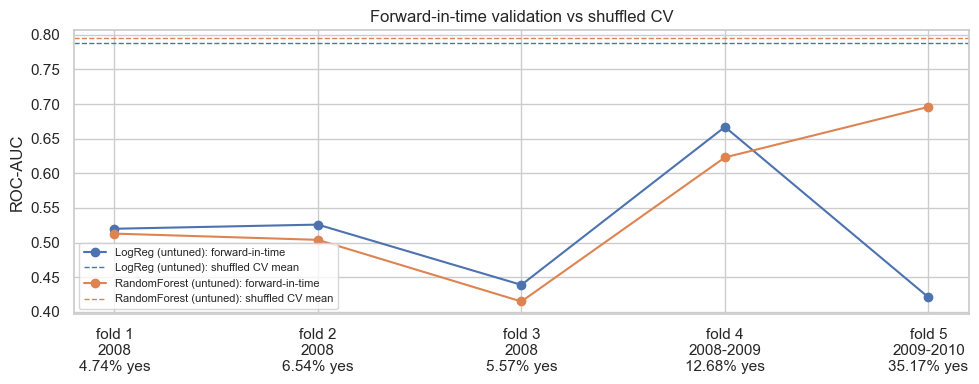

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, grp in time_folds.groupby("model"):
    ax.plot(grp["fold"], grp["roc_auc"], marker="o", label=f"{name}: forward-in-time")
    ax.axhline(shuffled.loc[name, "roc_auc_mean"], ls="--", lw=1,
               color=ax.lines[-1].get_color(), label=f"{name}: shuffled CV mean")
labels = time_folds.drop_duplicates("fold").set_index("fold")
ax.set_xticks(labels.index)
ax.set_xticklabels([f"fold {f}\n{labels.loc[f, 'val_period']}\n{labels.loc[f, 'val_yes_rate_%']}% yes" for f in labels.index])
ax.set_ylabel("ROC-AUC")
ax.set_title("Forward-in-time validation vs shuffled CV")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(config.FIGURES / "fig11_time_drift_validation.png", dpi=150, bbox_inches="tight")
plt.show()

**How this is used:** shuffled stratified CV stays the main scheme for comparing models (all models face the same conditions,
and the hold-out test set was drawn the same way). The forward-in-time results quantify how much performance may drop when the
model is applied to a **new period**, which is reported as a limitation and a monitoring/retraining recommendation.

## 7. Summary
Full details: `docs/validation_findings.txt`.

**Validation scheme (D18).** Stratified 5-fold CV (shuffled, seed 42) on the training set; every fold has 6,588 validation rows with 742–743 subscribers (11.26–11.28%). **PR-AUC is the primary metric**, top-20% capture is the business metric, and ROC-AUC, recall, precision, F1 and balanced accuracy are secondary. The test set is used once at the end.

**Reference floor.**
| | PR-AUC | ROC-AUC | Recall | Accuracy | Top-20% capture |
|---|---|---|---|---|---|
| Always "no" | 0.113 | 0.500 | 0.000 | **0.887** | 0.189 |
| Random guess | 0.113 | 0.502 | 0.114 | 0.802 | 0.199 |
| LogReg (untuned) | 0.437 | 0.788 | 0.625 | 0.820 | 0.620 |
| RandomForest (untuned) | 0.465 | 0.796 | 0.590 | 0.864 | 0.637 |

"Always no" has the highest accuracy of all and finds no subscribers, which shows accuracy is the wrong metric. Untuned models already find ~62–64% of subscribers in the top-scored 20% of clients (3.1–3.2× random calling).

**`duration` leakage confirmed in numbers (D3).** Adding `duration` would raise PR-AUC from 0.437 → 0.584 (LR) and 0.465 → 0.656 (RF), ROC-AUC to 0.94–0.95, and top-20% capture to 84–87%. That gain is impossible before a call, so `duration` stays excluded.

**Time-drift check (D12): the most important limitation found so far.**
- Forward-in-time CV gives a mean ROC-AUC of only **0.515 (LR) / 0.550 (RF)** vs 0.79–0.80 with shuffled CV; mean PR-AUC lift 1.1–1.2 vs 3.9–4.1.
- Why: (1) in 2008, the bank's first campaign period, only **2.7%** of clients had been contacted before (vs 32% in 2009, 59% in 2010), so the strongest client signal (`poutcome`, `contacted_before`) barely exists in the early folds; (2) every validation block contains **months never seen in training** (one-hot ignores them); (3) later blocks have **economic values outside the training range** (fold 5: euribor 0.63–1.29 vs training mostly above 1.27), and Logistic Regression extrapolates badly there (ROC-AUC 0.42), while RF holds up better (0.70).
- Early folds are a harsh test (they train on only 1–4 months), but the conclusion is clear: much of the shuffled-CV skill comes from **period/economic conditions and prior-campaign history**, and the model **cannot be trusted under new economic conditions without retraining on recent data**.
- **Decision:** shuffled stratified CV remains the scheme for comparing models (identical conditions for all models and consistent with the hold-out test set). The drift result is reported as a key limitation, with a recommendation for regular retraining and monitoring. A per-period check of the final model is added to the evaluation step.